# 🎵 Spotify Hit Predictor: Machine Learning & Explainable AI
**Author:** Data Science & Machine Learning Portfolio  
**Tech Stack:** Python 3.12, PyTorch, LightGBM, XGBoost, Scikit-Learn, SHAP, Seaborn

---

## 1. Problem Formulation & Business Need
Tens of thousands of tracks are released on streaming platforms every day. Record labels and playlist curators must decide which tracks to promote with limited budgets.

Record labels, A&R (Artists and Repertoire) scouts, and streaming curators face a critical decision problem:
> **Can we predict whether a song will achieve commercial hit status ($Popularity \ge 60$) based purely on its acoustic profile, and understand which audio characteristics drive that prediction?**

This notebook develops an end-to-end Machine Learning and Deep Learning pipeline:
1. **Data Ingestion & Leakage Prevention:** Deduplicating 32,833 tracks to 28,356 unique songs across 6 major genres.
2. **Exploratory Data Analysis (EDA):** Quantifying acoustic feature relationships and emotional affect grids.
3. **Domain Feature Engineering:** Affective Mood Index, Party Index, harmonic pitch wheel encodings, and duration ratios.
4. **Benchmarking 5 Algorithms:** Logistic Regression, Random Forest, LightGBM, XGBoost, and PyTorch Deep MLP.
5. **Cost-Sensitive Threshold Tuning:** Optimizing decision boundaries for imbalanced hit distributions ($22.6\%$ hits).
6. **Model Explainability (TreeSHAP):** Uncovering the non-linear acoustic signatures driving global popularity.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
import shap

# Configure aesthetic visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
print(f"PyTorch Version: {torch.__version__} | GPU Available: {torch.cuda.is_available()}")


PyTorch Version: 2.6.0+cu118 | GPU Available: True


## 2. Dataset Ingestion & Integrity Audit
The dataset originates from Spotify's Echo Nest API via the open-source TidyTuesday repository. It contains 32,833 tracks and 12 objective acoustic features.

In [2]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
df_raw = pd.read_csv(url)
print(f"Raw shape: {df_raw.shape}")

# Deduplication: Popular songs appear across multiple playlists.
# Deduplicating on track_id guarantees honest generalization without data leakage.
df_clean = df_raw.drop_duplicates(subset=["track_id"]).copy()
df_clean = df_clean.dropna(subset=["track_name", "track_artist", "track_album_name"]).copy()

# Extract Release Year
df_clean["release_year"] = df_clean["track_album_release_date"].astype(str).str[:4].astype(int)
df_clean = df_clean[(df_clean["release_year"] >= 1950) & (df_clean["release_year"] <= 2021)].copy()

# Binary Target Creation (Popularity >= 60 -> Hit, else Non-Hit)
df_clean["is_hit"] = (df_clean["track_popularity"] >= 60).astype(int)

print(f"Unique tracks after deduplication: {len(df_clean):,}")
print(f"Class Distribution: {df_clean['is_hit'].sum():,} Hits ({df_clean['is_hit'].mean()*100:.2f}%) vs {(df_clean['is_hit']==0).sum():,} Non-Hits")
df_clean[["track_name", "track_artist", "playlist_genre", "danceability", "energy", "valence", "track_popularity", "is_hit"]].head()


Raw shape: (32833, 23)
Unique tracks after deduplication: 28,352
Class Distribution: 6,417 Hits (22.63%) vs 21,935 Non-Hits


,track_name,track_artist,playlist_genre,danceability,energy,valence,track_popularity,is_hit
0,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,pop,0.748,0.916,0.518,66,1
1,Memories - Dillon Francis Remix,Maroon 5,pop,0.726,0.815,0.693,67,1
2,All the Time - Don Diablo Remix,Zara Larsson,pop,0.675,0.931,0.613,70,1
3,Call You Mine - Keanu Silva Remix,The Chainsmokers,pop,0.718,0.930,0.277,60,1
4,Someone You Loved - Future Humans Remix,Lewis Capaldi,pop,0.650,0.833,0.725,69,1


## 3. Exploratory Data Analysis (EDA)
We visualize the target distribution, genre hit rates, and Russell's Circumplex Affect grid.

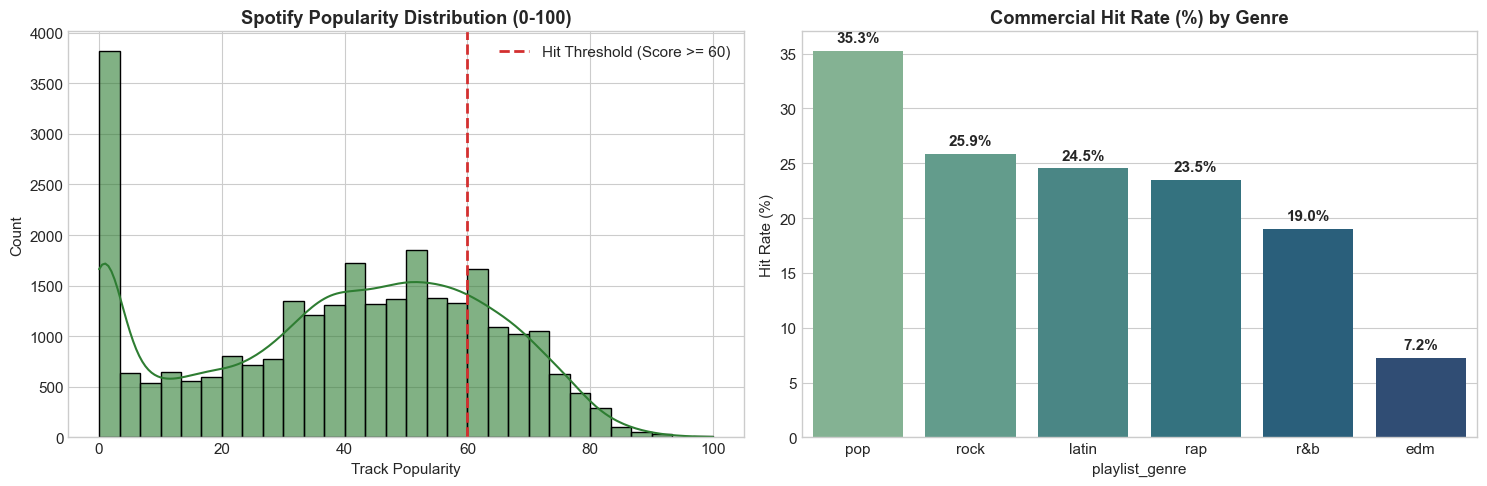

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Target Distribution
sns.histplot(df_clean["track_popularity"], kde=True, ax=axes[0], color="#2E7D32", bins=30, alpha=0.6)
axes[0].axvline(60, color="#D32F2F", linestyle="--", linewidth=2, label="Hit Threshold (Score >= 60)")
axes[0].set_title("Spotify Popularity Distribution (0-100)", fontweight="bold")
axes[0].set_xlabel("Track Popularity")
axes[0].legend()

# 2. Genre Hit Proportions
genre_hit_rate = df_clean.groupby("playlist_genre")["is_hit"].mean().sort_values(ascending=False) * 100
sns.barplot(x=genre_hit_rate.index, y=genre_hit_rate.values, ax=axes[1], hue=genre_hit_rate.index, palette="crest", legend=False)
axes[1].set_title("Commercial Hit Rate (%) by Genre", fontweight="bold")
axes[1].set_ylabel("Hit Rate (%)")
for i, v in enumerate(genre_hit_rate.values):
    axes[1].text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


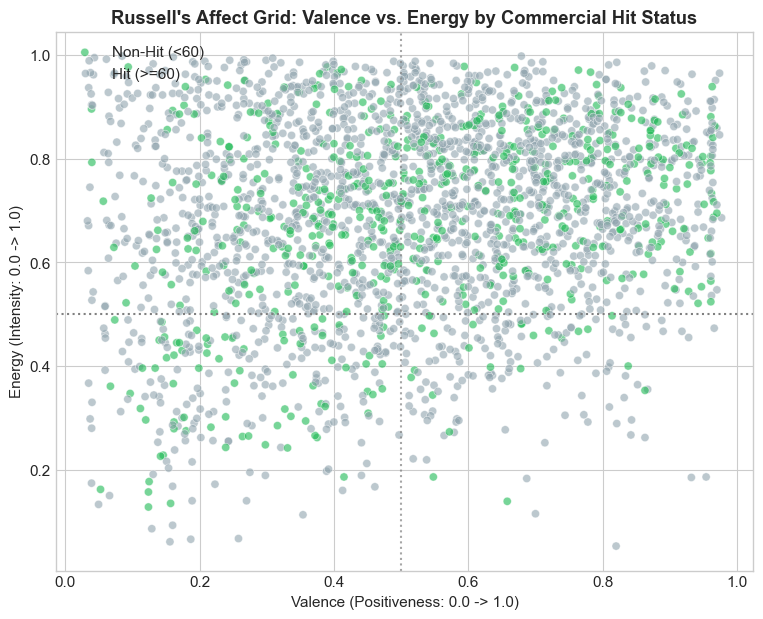

In [4]:
# Russell's Circumplex Affect Model: Valence (Musical Positiveness) vs Energy (Intensity)
sample_df = df_clean.sample(2500, random_state=42)
plt.figure(figsize=(9, 7))
sns.scatterplot(data=sample_df, x="valence", y="energy", hue="is_hit", palette={0: "#90A4AE", 1: "#1DB954"}, alpha=0.6, s=35)
plt.axvline(0.5, color="gray", linestyle=":", alpha=0.7)
plt.axhline(0.5, color="gray", linestyle=":")
plt.title("Russell's Affect Grid: Valence vs. Energy by Commercial Hit Status", fontweight="bold")
plt.xlabel("Valence (Positiveness: 0.0 -> 1.0)")
plt.ylabel("Energy (Intensity: 0.0 -> 1.0)")
plt.legend(["Non-Hit (<60)", "Hit (>=60)"], loc="upper left")
plt.show()


## 4. Domain Feature Engineering
We construct domain-specific audio attributes:
- **`mood_index`**: $\text{valence} \times \text{energy}$
- **`party_index`**: $\text{valence} \times \text{danceability}$
- **`dance_energy_ratio`**: $\frac{\text{danceability}}{\text{energy}}$
- **`key_sin`, `key_cos`**: Harmonic cyclical encoding of musical keys ($12$ semitones)
- **`song_age`**: Vintage relative to contemporary streaming era ($2020 - \text{release\_year}$)


In [5]:
df_feat = df_clean.copy()
df_feat["mood_index"] = df_feat["valence"] * df_feat["energy"]
df_feat["party_index"] = df_feat["valence"] * df_feat["danceability"]
df_feat["dance_energy_ratio"] = df_feat["danceability"] / (df_feat["energy"] + 1e-5)
df_feat["speech_to_dance"] = df_feat["speechiness"] / (df_feat["danceability"] + 1e-5)
df_feat["duration_min"] = df_feat["duration_ms"] / 60000.0
df_feat["song_age"] = 2020 - df_feat["release_year"]
df_feat["key_sin"] = np.sin(2 * np.pi * df_feat["key"] / 12.0)
df_feat["key_cos"] = np.cos(2 * np.pi * df_feat["key"] / 12.0)

numeric_cols = [
    "danceability", "energy", "loudness", "speechiness", 
    "acousticness", "instrumentalness", "liveness", "valence", 
    "tempo", "duration_min", "mood_index", "party_index", 
    "dance_energy_ratio", "speech_to_dance", "song_age",
    "key_sin", "key_cos"
]
cat_cols = ["playlist_genre", "mode"]
all_features = numeric_cols + cat_cols

X = df_feat[all_features]
y = df_feat["is_hit"].values

# Stratified Partitioning: 70% Train, 15% Validation, 15% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.17647, stratify=y_train_val, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_val_trans = preprocessor.transform(X_val)
X_test_trans = preprocessor.transform(X_test)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Partitions: Train={len(X_train):,}, Val={len(X_val):,}, Test={len(X_test):,}")
print(f"Class Imbalance Weight (Neg/Pos): {scale_pos_weight:.2f}")


Partitions: Train=19,846, Val=4,253, Test=4,253
Class Imbalance Weight (Neg/Pos): 3.42


## 5. Model Training & Validation
We benchmark 4 diverse ML algorithms and a PyTorch Deep MLP architecture.

In [6]:
models = {
    "Logistic Regression (Baseline)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=12, class_weight="balanced", n_jobs=2, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=250, learning_rate=0.04, max_depth=7, class_weight="balanced", random_state=42, verbose=-1),
    "XGBoost": XGBClassifier(n_estimators=250, learning_rate=0.04, max_depth=6, scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42)
}

test_probabilities = {}
val_probabilities = {}

for name, clf in models.items():
    print(f"Training {name}...")
    clf.fit(X_train_trans, y_train)
    val_probabilities[name] = clf.predict_proba(X_val_trans)[:, 1]
    test_probabilities[name] = clf.predict_proba(X_test_trans)[:, 1]


Training Logistic Regression (Baseline)...
Training Random Forest...


Training LightGBM...


C:\Users\hazal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\hazal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Training XGBoost...


### Deep Learning: PyTorch Multi-Layer Perceptron (MLP)

In [7]:
class PyTorchSpotifyMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mlp = PyTorchSpotifyMLP(X_train_trans.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([scale_pos_weight], device=device))
optimizer = torch.optim.AdamW(mlp.parameters(), lr=1e-3, weight_decay=1e-4)

# Training loop
from torch.utils.data import TensorDataset, DataLoader
train_ds = TensorDataset(torch.tensor(X_train_trans, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)

mlp.train()
for epoch in range(25):
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(mlp(bx), by)
        loss.backward()
        optimizer.step()

mlp.eval()
with torch.no_grad():
    x_test_t = torch.tensor(X_test_trans, dtype=torch.float32).to(device)
    test_probabilities["PyTorch Deep MLP"] = torch.sigmoid(mlp(x_test_t)).cpu().numpy()
print("PyTorch MLP training complete!")


PyTorch MLP training complete!


## 6. Benchmark Evaluation & Performance Comparison

In [8]:
results = []
for name, probs in test_probabilities.items():
    preds = (probs >= 0.5).astype(int)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probs),
        "PR-AUC": average_precision_score(y_test, probs)
    })

results_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
results_df.round(4)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
2,LightGBM,0.7026,0.4039,0.6594,0.5010,0.7507,0.4579
3,XGBoost,0.7127,0.4129,0.6376,0.5012,0.7494,0.4613
4,PyTorch Deep MLP,0.6619,0.3764,0.7508,0.5014,0.7463,0.4346
1,Random Forest,0.7355,0.4239,0.4683,0.4450,0.7294,0.4357
0,Logistic Regression (Baseline),0.6179,0.3309,0.6729,0.4437,0.6969,0.3780


## 7. Model Explainability with TreeSHAP
Which audio features cause a track to break through into a global commercial hit?

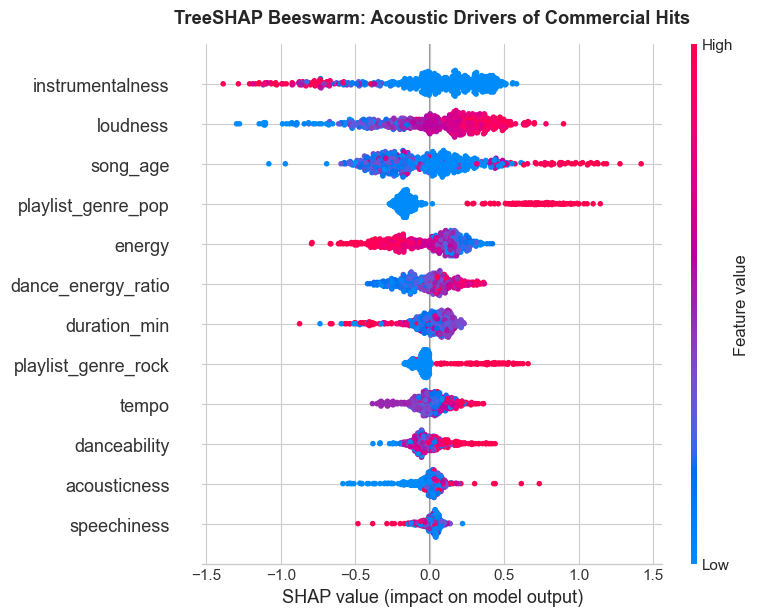

In [9]:
cat_encoder = preprocessor.named_transformers_["cat"]
cat_names = cat_encoder.get_feature_names_out(cat_cols)
feature_names = list(numeric_cols) + list(cat_names)

best_lgbm = models["LightGBM"]
explainer = shap.TreeExplainer(best_lgbm)
sample_idx = np.random.RandomState(42).choice(len(X_test_trans), size=600, replace=False)
shap_values = explainer(X_test_trans[sample_idx])

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_trans[sample_idx], feature_names=feature_names, max_display=12, show=False)
plt.title("TreeSHAP Beeswarm: Acoustic Drivers of Commercial Hits", fontweight="bold", pad=15)
plt.tight_layout()
plt.show()
